In [2]:
import os
import sys
import ast
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import proplot as pplt
from joblib import Parallel,delayed
from scipy.optimize import minimize
sys.path.insert(0,'..')
from scripts.utils import Config,load_stats
from scripts.models.sr.train import load_features
from scripts.models.sr.optimize import calc_loss
from scripts.models.sr.equations import evaluate,raw_to_precip,round_constants,load_registry
warnings.filterwarnings('ignore')
pplt.rc.update({
    'savefig.dpi':900,
    'savefig.bbox':'tight',
    'savefig.pad_inches':0.02,
    'tick.minor':False,
    'font.size':9,
    'label.size':9,
    'tick.labelsize':9,
    'title.size':9,
    'abc.size':9,
    'legend.fontsize':9,
    'suptitle.size':9,
    'leftlabelsize':9,
    'toplabelsize':9,
    'leftlabel.weight':'normal',
    'toplabel.weight':'normal',
    'reso':'xx-hi'})

In [3]:
CONFIG       = Config()
SR           = CONFIG.sr
STATS        = load_stats(CONFIG.splitsdir)
REGISTRY     = load_registry(CONFIG.modelsdir)
TARGETVAR    = CONFIG.targetvar
ZMIN         = (0.0-STATS[f'{TARGETVAR}_mean'])/STATS[f'{TARGETVAR}_std']
ATMRUN       = SR['runs']['sr_atm']
ATMEQ        = SR['optimizedeqs']['sr_atm_eq']
ATMCONSTANTS = REGISTRY['sr_atm_eq']['constants']
NNRUNS       = CONFIG.nn['runs']
EQUATIONS    = SR['optimizedeqs']
NRESTARTS    = SR['nrestarts']
INITSCALE    = SR['initscale']
SIGFIGS      = SR['constantsigfigs']
NWORKERS     = int(os.environ.get('SLURM_CPUS_PER_TASK',os.cpu_count()))
OPCOMPLEXITY = {**SR['operators']['complexity'],'log':2}
VARCOMPLEXITY = SR['complexity']['ofvariables']
SPLIT        = 'test'
R2REFS       = [0.25,0.5]
SAVEPATH     = os.path.join(CONFIG.modelsdir,'sr','sr_atm_alternatives.csv')
FIGPATH      = '../figs/fig_sratm_alternatives.jpg'
INSTABILITY  = 'thetae-c4*thetaestar-c5'
FORMS = {
    'sr_atm_add_eq':dict(
        label='SR-ATM (additive)',color='#6FA8DC',marker='s',
        form=f'c3*cube(c6*rh+{INSTABILITY})',
        compact=f'c3*cube(c6*rh+{INSTABILITY})',
        starts=[('SR-ATM constants',{**ATMCONSTANTS,'c6':1.0}),
                ('PySR seed 42, complexity 16',{'c3':1.0,'c4':1.4615,'c5':0.2527,'c6':0.1599})]),
    'sr_atm_sumcube_eq':dict(
        label='SR-ATM (sum of cubes)',color='#3D85C6',marker='s',
        form=f'c3*(cube(c6*rh)+cube({INSTABILITY}))',
        compact=f'c3*(cube(c6*rh)+cube({INSTABILITY}))',
        starts=[('SR-ATM constants',{**ATMCONSTANTS,'c6':1.0}),
                ('PySR seed 72, complexity 16',{'c3':0.5878,'c4':1.4377,'c5':0.0,'c6':1.0}),
                ('PySR seed 102, complexity 14',{'c3':0.4787,'c4':1.2783,'c5':0.0,'c6':1.2783})]),
    'sr_atm_smoothmax_eq':dict(
        label='SR-ATM (smooth max)',color='#0B5394',marker='s',
        form=f'c3*cube(max(rh,{INSTABILITY})+abs(c6)*log(1+exp(-abs(rh-({INSTABILITY}))/(abs(c6)+1e-12))))',
        compact=f'c3*cube(c6*log(exp(rh/c6)+exp(({INSTABILITY})/c6)))',
        starts=[(f'SR-ATM constants, c6 = {width}',{**ATMCONSTANTS,'c6':width}) for width in (0.01,0.1,1.0)])}

In [4]:
def calc_complexity(form):
    def count(node):
        if isinstance(node,ast.Expression):
            return count(node.body)
        if isinstance(node,ast.BinOp):
            op = {ast.Add:'+',ast.Sub:'-',ast.Mult:'*',ast.Div:'/',ast.Pow:'^'}[type(node.op)]
            return OPCOMPLEXITY[op]+count(node.left)+count(node.right)
        if isinstance(node,ast.UnaryOp):
            return OPCOMPLEXITY['neg']+count(node.operand)
        if isinstance(node,ast.Call):
            return OPCOMPLEXITY[node.func.id]+sum(count(arg) for arg in node.args)
        if isinstance(node,ast.Name):
            return VARCOMPLEXITY.get(node.id,SR['complexity']['ofconstants'])
        return SR['complexity']['ofconstants']
    return count(ast.parse(form,mode='eval'))

def make_starts(starts,constantnames,nstarts,initscale):
    inits = [dict(source=source,constants={c:float(constants[c]) for c in constantnames}) for source,constants in starts]
    rng   = np.random.default_rng(0)
    while len(inits)<nstarts:
        inits.append(dict(source='random',constants=dict(zip(constantnames,rng.uniform(-initscale,initscale,len(constantnames)).tolist()))))
    return inits

def fit_starts(form,inits,columns,y,zmin,nworkers):
    names = list(inits[0]['constants'])
    def run(init):
        x0  = np.array([init['constants'][c] for c in names])
        res = minimize(lambda params:calc_loss(form,columns,y,zmin,dict(zip(names,params))),x0,
                       method='L-BFGS-B',options={'maxiter':10000,'ftol':1e-14,'gtol':1e-10})
        return dict(source=init['source'],initloss=calc_loss(form,columns,y,zmin,init['constants']),loss=float(res.fun),
                    nit=int(res.nit),converged=bool(res.success),maxshift=float(np.max(np.abs(res.x-x0))),
                    **{f'{c}_init':float(v) for c,v in zip(names,x0)},**{c:float(v) for c,v in zip(names,res.x)})
    return pd.DataFrame(Parallel(n_jobs=nworkers,prefer='threads')(delayed(run)(init) for init in inits))

def calc_seed_mean(ytrue,ypred):
    scores = []
    for seed in (ypred['seed'].values if 'seed' in ypred.dims else [None]):
        seedtrue,seedpred = xr.align(ytrue,(ypred if seed is None else ypred.sel(seed=seed)).squeeze(),join='inner')
        if int(seedpred.count())==0:
            continue
        sqerr = (seedtrue.squeeze()-seedpred)**2
        scores.append((float(1-sqerr.sum()/((seedtrue-seedtrue.mean())**2).sum()),float(sqerr.mean())))
    return tuple(np.mean(scores,axis=0)) if scores else (np.nan,np.nan)

def to_grid(raw,validmask,refda):
    grid = np.full(validmask.shape,np.nan)
    grid[validmask] = raw_to_precip(raw,STATS[f'{TARGETVAR}_std'])
    return xr.DataArray(grid.reshape(refda.shape),dims=refda.dims,coords=refda.coords)

In [5]:
complexities = {'sr_atm_eq':calc_complexity(ATMEQ['form']),**{name:calc_complexity(spec['compact']) for name,spec in FORMS.items()}}
print(f"SR-ATM complexity: {complexities['sr_atm_eq']} (configured refcomplexity: {ATMEQ['refcomplexity']})")
for name,spec in FORMS.items():
    print(f"{spec['label']}: complexity {complexities[name]}")

SR-ATM complexity: 17 (configured refcomplexity: 17)
SR-ATM (additive): complexity 18
SR-ATM (sum of cubes): complexity 20
SR-ATM (smooth max): complexity 30


In [6]:
rng       = np.random.default_rng(1)
nsynth    = 50000
latent    = rng.standard_normal(nsynth)
synthcols = {'rh':0.8*latent+0.6*rng.standard_normal(nsynth),
             'thetae':0.7*latent+0.7*rng.standard_normal(nsynth),
             'thetaestar':0.3*latent+0.95*rng.standard_normal(nsynth)}
truths    = {'sr_atm_add_eq':{'c3':0.9,'c4':1.2,'c5':0.4,'c6':0.5},
             'sr_atm_sumcube_eq':{'c3':0.7,'c4':1.3,'c5':0.2,'c6':0.8},
             'sr_atm_smoothmax_eq':{'c3':1.2,'c4':1.4,'c5':0.3,'c6':0.4}}
for name,spec in FORMS.items():
    truth     = truths[name]
    synthy    = ZMIN+np.maximum(evaluate(spec['form'],synthcols,truth),0.0)+0.05*rng.standard_normal(nsynth)
    source,start = spec['starts'][0]
    fit       = fit_starts(spec['form'],[dict(source=source,constants={c:start[c] for c in truth})],synthcols,synthy,ZMIN,1).iloc[0]
    error     = max(abs(abs(fit[c])-abs(truth[c])) if c=='c6' else abs(fit[c]-truth[c]) for c in truth)
    print(f"{spec['label']}: start {start} -> fit {({c:round(fit[c],3) for c in truth})} vs truth {truth} | "
          f"loss {fit['initloss']:.4f} -> {fit['loss']:.4f} in {fit['nit']} iterations | max error {error:.3f}")
    assert fit['nit']>0 and fit['maxshift']>1e-3 and error<0.05,f'{name}: synthetic recovery failed'
synthy = ZMIN+np.maximum(evaluate(ATMEQ['form'],synthcols,{'c3':1.2,'c4':1.4,'c5':0.3}),0.0)+0.05*rng.standard_normal(nsynth)
source,start = FORMS['sr_atm_smoothmax_eq']['starts'][-1]
fit    = fit_starts(FORMS['sr_atm_smoothmax_eq']['form'],[dict(source=source,constants=start)],synthcols,synthy,ZMIN,1).iloc[0]
print(f"Smooth max on sharp-max data: c6 {start['c6']} -> {abs(fit['c6']):.4f} in {fit['nit']} iterations")
assert abs(fit['c6'])<0.02,'smooth max did not collapse to the sharp max'

SR-ATM (additive): start {'c3': 1.58, 'c4': 1.452, 'c5': 0.3409, 'c6': 1.0} -> fit {'c3': 0.9, 'c4': 1.2, 'c5': 0.4, 'c6': 0.5} vs truth {'c3': 0.9, 'c4': 1.2, 'c5': 0.4, 'c6': 0.5} | loss 425.0351 -> 0.0025 in 21 iterations | max error 0.000
SR-ATM (sum of cubes): start {'c3': 1.58, 'c4': 1.452, 'c5': 0.3409, 'c6': 1.0} -> fit {'c3': 0.7, 'c4': 1.3, 'c5': 0.2, 'c6': 0.8} vs truth {'c3': 0.7, 'c4': 1.3, 'c5': 0.2, 'c6': 0.8} | loss 77.1106 -> 0.0025 in 21 iterations | max error 0.000
SR-ATM (smooth max): start {'c3': 1.58, 'c4': 1.452, 'c5': 0.3409, 'c6': 0.01} -> fit {'c3': 1.2, 'c4': 1.4, 'c5': 0.3, 'c6': 0.4} vs truth {'c3': 1.2, 'c4': 1.4, 'c5': 0.3, 'c6': 0.4} | loss 13.8354 -> 0.0025 in 29 iterations | max error 0.000
Smooth max on sharp-max data: c6 1.0 -> 0.0009 in 30 iterations


In [7]:
xtrain,ytrain,reftrain,trainmask = load_features('train',ATMRUN,CONFIG,timeoffset=0)
xvalid,yvalid,_,validmask        = load_features('valid',ATMRUN,CONFIG,timeoffset=int(reftrain.sizes['time']))
xtest,ytest,reftest,testmask     = load_features(SPLIT,ATMRUN,CONFIG)
predictornames = [c for c in xtrain.columns if c!='timeidx']
fitcols   = {c:np.concatenate([xtrain[c].values[trainmask],xvalid[c].values[validmask]]) for c in predictornames}
validcols = {c:xvalid[c].values[validmask] for c in predictornames}
testcols  = {c:xtest[c].values[testmask] for c in predictornames}
yfit      = np.concatenate([ytrain[trainmask],yvalid[validmask]])
yval      = yvalid[validmask]
ytest     = ytest[testmask]
del xtrain,xvalid,xtest,ytrain,yvalid,reftrain
atmloss   = calc_loss(ATMEQ['form'],fitcols,yfit,ZMIN,ATMCONSTANTS)
print(f"{len(yfit):,} fitting samples | SR-ATM training loss {atmloss:.6f} (registry: {REGISTRY['sr_atm_eq']['train_loss']:.6f})")

8,624,448 fitting samples | SR-ATM training loss 0.450321 (registry: 0.450321)


In [8]:
saved   = pd.read_csv(SAVEPATH).set_index('name') if os.path.exists(SAVEPATH) else pd.DataFrame()
results = {}
for name,spec in FORMS.items():
    constantnames = sorted(spec['starts'][0][1])
    if name in saved.index:
        print(f"Skipping {spec['label']}, already optimized")
        results[name] = {c:float(saved.loc[name,c]) for c in constantnames}
        continue
    print(f"Optimizing {spec['label']} from {NRESTARTS} starts with {NWORKERS} worker(s)...")
    fits = fit_starts(spec['form'],make_starts(spec['starts'],constantnames,NRESTARTS,INITSCALE),fitcols,yfit,ZMIN,NWORKERS)
    print(fits[fits['source']!='random'][['source','initloss','loss','nit','converged','maxshift']].to_string(index=False))
    print(f"Random starts: best loss {fits.loc[fits['source']=='random','loss'].min():.6f}, "
          f"{int((fits.loc[fits['source']=='random','loss']<fits['loss'].min()+1e-4).sum())} within 1e-4 of the best")
    best = fits.loc[fits['loss'].idxmin()]
    if best['nit']==0 or best['maxshift']<1e-6:
        print(f"WARNING: best start for {spec['label']} did not move its constants")
    constants = round_constants({c:best[c] for c in constantnames},SIGFIGS)
    if name=='sr_atm_smoothmax_eq':
        constants['c6'] = abs(constants['c6'])
    results[name] = constants
    row = dict(name=name,form=spec['form'],compact=spec['compact'],complexity=complexities[name],beststart=best['source'],
               train_loss=calc_loss(spec['form'],fitcols,yfit,ZMIN,constants),valid_loss=calc_loss(spec['form'],validcols,yval,ZMIN,constants),**constants)
    print(f"   Best start: {best['source']} | rounded constants {constants} | training loss {row['train_loss']:.6f}")
    saved = pd.concat([saved.drop(index=name,errors='ignore'),pd.DataFrame([row]).set_index('name')])
    saved.to_csv(SAVEPATH)
    if name not in pd.read_csv(SAVEPATH)['name'].values:
        raise ValueError(f'{SAVEPATH} does not contain {name}')

Optimizing SR-ATM (additive) from 50 starts with 256 worker(s)...
                     source  initloss     loss  nit  converged  maxshift
           SR-ATM constants 18.016210 0.467092   28       True  0.828959
PySR seed 42, complexity 16  0.467305 0.467092   15      False  0.071016
Random starts: best loss 0.467092, 15 within 1e-4 of the best
   Best start: random | rounded constants {'c3': 0.929, 'c4': 1.464, 'c5': 0.2267, 'c6': 0.171} | training loss 0.467092
Optimizing SR-ATM (sum of cubes) from 50 starts with 256 worker(s)...
                      source  initloss     loss  nit  converged  maxshift
            SR-ATM constants  0.663976 0.455706   21       True  0.295405
 PySR seed 72, complexity 16  0.466579 0.455706   22       True  0.696799
PySR seed 102, complexity 14  0.487946 0.455706   25       True  0.805896
Random starts: best loss 0.455706, 21 within 1e-4 of the best
   Best start: random | rounded constants {'c3': 1.285, 'c4': 1.461, 'c5': 0.3123, 'c6': 0.7873} | train

In [9]:
truetp = reftest
scores = {}
for name,form,constants in [('sr_atm_eq',ATMEQ['form'],ATMCONSTANTS)]+[(name,spec['form'],results[name]) for name,spec in FORMS.items()]:
    r2,mse = calc_seed_mean(truetp,to_grid(evaluate(form,testcols,constants),testmask,reftest))
    scores[name] = dict(model=FORMS[name]['label'] if name in FORMS else 'SR-ATM (max)',complexity=complexities[name],
                        nconstants=len(constants),fitloss=calc_loss(form,fitcols,yfit,ZMIN,constants),
                        testloss=calc_loss(form,testcols,ytest,ZMIN,constants),r2=r2,mse=mse,
                        constants=constants)
table = pd.DataFrame(scores).T
print(table[['model','complexity','nconstants','fitloss','testloss','r2','mse']].to_string())
print(f"Smooth-max width c6 = {results['sr_atm_smoothmax_eq']['c6']} (standardized), "
      f"{results['sr_atm_smoothmax_eq']['c6']*STATS['thetae_std']:.3f} K")

                                     model complexity nconstants   fitloss  testloss        r2       mse
sr_atm_eq                     SR-ATM (max)         17          3  0.450321  0.490888  0.321741  3.004601
sr_atm_add_eq            SR-ATM (additive)         18          4  0.467092   0.50584   0.27297  3.220651
sr_atm_sumcube_eq    SR-ATM (sum of cubes)         20          4  0.455707   0.49424  0.306767  3.070934
sr_atm_smoothmax_eq    SR-ATM (smooth max)         30          4  0.446634  0.485116  0.325794  2.986649
Smooth-max width c6 = 0.1148 (standardized), 1.036 K


In [10]:
MODELINFO = {**{name:dict(label=run['description'],color=run['color'],marker='D') for name,run in NNRUNS.items()},
             **{name:dict(label=eq['description'],color=eq['color'],marker='o') for name,eq in EQUATIONS.items()}}
with xr.open_dataset(os.path.join(CONFIG.splitsdir,'train.h5'),engine='h5netcdf') as ds:
    nsigs = ds.sizes['sig']
pareto = {}
for name in MODELINFO:
    path = os.path.join(CONFIG.predsdir,f'{name}_{SPLIT}_predictions.nc')
    if not os.path.exists(path):
        continue
    with xr.open_dataset(path) as ds:
        predtp = ds['tp'].load()
    if name in NNRUNS:
        run        = NNRUNS[name]
        nfieldvars = len(run['fieldvars'])
        nlocalvars = len(run.get('localvars',[]))
        ninputs    = nfieldvars*nsigs+nlocalvars if run['kind']=='baseline' else nfieldvars+nlocalvars
        nkernel    = {'baseline':0,'nonparametric':nfieldvars*nsigs,'parametric':2*nfieldvars}[run['kind']]
        nparams    = nkernel+ninputs*256+256+256*128+128+128*64+64+64*32+32+32+1
    else:
        nparams = EQUATIONS[name].get('complexity') or EQUATIONS[name]['refcomplexity']
        if 'sr_atm_eq' in EQUATIONS[name]['form']:
            nparams += EQUATIONS['sr_atm_eq']['refcomplexity']
    r2,mse = calc_seed_mean(truetp,predtp)
    pareto[name] = dict(r2=r2,mse=mse,nparams=nparams,**MODELINFO[name])
for name,spec in FORMS.items():
    pareto[name] = dict(r2=scores[name]['r2'],mse=scores[name]['mse'],nparams=complexities[name],label=spec['label'],color=spec['color'],marker=spec['marker'])
print(f'{len(pareto)} models loaded!')

front,best = [],np.inf
for candidate in sorted(pareto.values(),key=lambda r:r['mse']):
    if candidate['nparams']<best:
        front.append(candidate)
        best = candidate['nparams']
front      = sorted(front,key=lambda r:r['nparams'])
ymax       = 3*max(r['nparams'] for r in pareto.values())
frontmse   = [999]+[r['mse'] for r in front]+[front[-1]['mse']]
frontcount = [front[0]['nparams']]+[r['nparams'] for r in front]+[ymax]
sstot      = float(((truetp-truetp.mean())**2).sum())
mserefs    = {r2:(1-r2)*sstot/int(truetp.count()) for r2 in R2REFS}

12 models loaded!


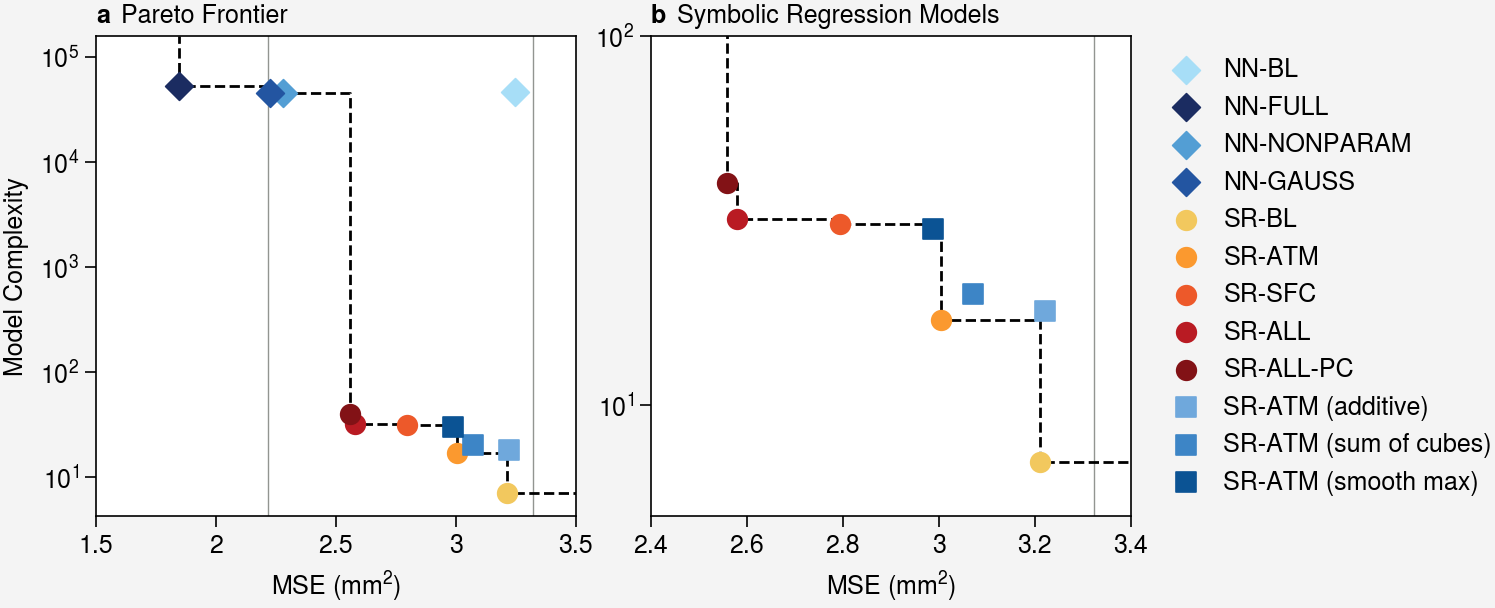

In [11]:
fig,axs = pplt.subplots(ncols=2,refwidth=2.4,refheight=2.4,share=False,wspace=3)
for ax,xlim,ylim in zip(axs,[(1.5,3.5),(2.4,3.4)],[(None,ymax),(5,100)]):
    ax.plot(frontmse,frontcount,color='k',linestyle='--',linewidth=1,zorder=3,drawstyle='steps-pre')
    for r in pareto.values():
        ax.scatter(r['mse'],r['nparams'],color=r['color'],marker=r['marker'],markersize=50,zorder=6,label=r['label'] if ax is axs[1] else None)
    for r2,mse in mserefs.items():
        ax.axvline(mse,color='gray',linewidth=0.5)
    ax.format(grid=False,xlabel=r'MSE (mm$^2$)',xlim=xlim,ylim=ylim,yscale='log',yformatter='log')
axs[0].format(title='Pareto Frontier',ylabel='Model Complexity')
axs[1].format(title='Symbolic Regression Models')
axs[1].legend(loc='r',ncols=1,frame=False)
fig.format(abc=True,titleloc='l')
pplt.show()
fig.save(FIGPATH)